# Simulated person: linear observer in a 2IFC RC task

Implements the model in [model/01-simulated-person-on-paper.md](../model/01-simulated-person-on-paper.md), one function at a time.

| Equation | Function | Status |
|---|---|---|
| θ random, length 1 | `make_template(d)` | ✅ this notebook |
| n ~ N(0, I) | `make_noise(n_trials, d)` | ✅ this notebook |
| choose the top k of n noisy scores (2IFC: base + n if θᵀn + ε > 0) | `observer_choose(images, theta, sigma, k)`, `choices_to_sign(chosen)` | ✅ this notebook |
| CI = Σ s·n | `classification_image(noise, choices)` | ✅ this notebook |
| cos(CI, θ) | `cosine(a, b)` | ✅ this notebook |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 2026
rng = np.random.default_rng(SEED)

In [2]:
def _check_positive_int(name, value):
    """Raise ValueError unless value is a positive integer (rejects bool, float and None)."""
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f"{name} must be a positive integer, got {value!r}")

## 1. `make_template(d)` → θ

The hidden template θ is a **random unit vector** in d dimensions:

1. draw g ~ N(0, I_d);
2. set θ = g / ‖g‖.

Because N(0, I) is spherically symmetric, θ is **uniform over the unit sphere**: no direction is favoured.

In [3]:
def make_template(d, rng=None):
    """Return a random unit vector θ of shape (d,), uniform over the sphere in R^d.

    Parameters
    ----------
    d : int
        Number of dimensions of the stimulus space (d >= 1).
    rng : None, int or np.random.Generator, optional
        Seed or generator, for reproducible runs (passed to np.random.default_rng).
    """
    _check_positive_int("d", d)
    rng = np.random.default_rng(rng)
    g = rng.standard_normal(d)
    return g / np.linalg.norm(g)

## 2. Checks

In [4]:
d = 10
theta = make_template(d, rng)
print("theta =", np.round(theta, 3))
print("shape =", theta.shape, "| norm =", np.linalg.norm(theta))

# Unit length
assert theta.shape == (d,)
assert np.isclose(np.linalg.norm(theta), 1.0)

# Reproducible: same seed -> same template
a = make_template(d, np.random.default_rng(1))
b = make_template(d, np.random.default_rng(1))
assert np.array_equal(a, b)
assert np.array_equal(a, make_template(d, 1))   # an int seed works too

# Bad input is rejected
for bad in (0, -3, 2.5, True, None):
    try:
        make_template(bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"make_template({bad}) should fail")
print("All checks passed.")

theta = [-0.299  0.091 -0.715  0.526  0.241 -0.11  -0.118  0.115 -0.101 -0.085]
shape = (10,) | norm = 1.0
All checks passed.


### Is θ really uniform on the sphere?

Draw many templates. If θ is uniform:

- every coordinate has mean ≈ 0 and variance ≈ 1/d;
- the cosine between two independent templates (a pure "random guess" in §4 of the model) has **mean ≈ 0**, mean |cos| ≈ 0.26 and **RMS ≈ 1/√d ≈ 0.32** for d = 10.

max |mean of a coordinate| : 0.0035
variance per coordinate    : [0.1015 0.1    0.1007 0.1005 0.0988 0.1001 0.0991 0.0985 0.1011 0.0996] (expected 0.1000)

random-guess cosine: mean = 0.000, mean |cos| = 0.258, RMS = 0.314 (1/sqrt(d) = 0.316)


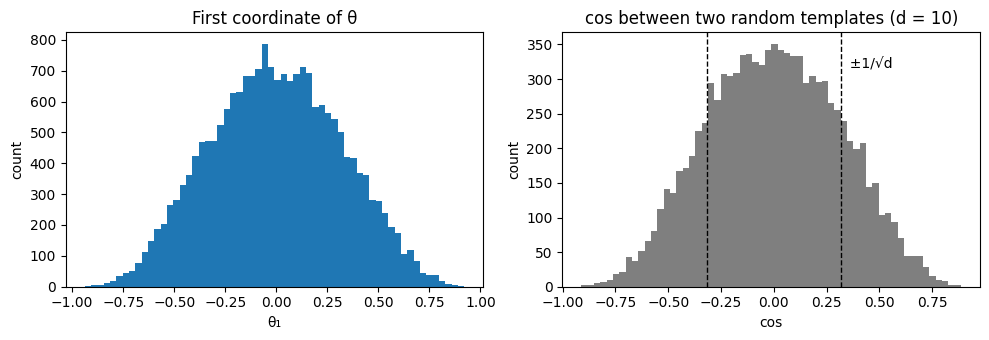

In [5]:
n_templates = 20_000
thetas = np.stack([make_template(d, rng) for _ in range(n_templates)])

print("max |mean of a coordinate| :", np.abs(thetas.mean(axis=0)).max().round(4))
print("variance per coordinate    :", thetas.var(axis=0).round(4), f"(expected {1/d:.4f})")

# Cosine between pairs of independent templates (all unit length, so cos = dot product)
cos_random = np.sum(thetas[0::2] * thetas[1::2], axis=1)
print(f"\nrandom-guess cosine: mean = {cos_random.mean():.3f}, "
      f"mean |cos| = {np.abs(cos_random).mean():.3f}, "
      f"RMS = {np.sqrt(np.mean(cos_random**2)):.3f} (1/sqrt(d) = {1/np.sqrt(d):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(thetas[:, 0], bins=60, color="tab:blue")
axes[0].set(title="First coordinate of θ", xlabel="θ₁", ylabel="count")
axes[1].hist(cos_random, bins=60, color="tab:gray")
for x in (-1/np.sqrt(d), 1/np.sqrt(d)):
    axes[1].axvline(x, ls="--", color="k", lw=1)
axes[1].set(title=f"cos between two random templates (d = {d})", xlabel="cos", ylabel="count")
axes[1].text(1/np.sqrt(d), axes[1].get_ylim()[1]*0.9, "  ±1/√d", va="top")
plt.tight_layout()
plt.show()

## 3. `make_noise(n_trials, d)` → noise vectors

One noise pattern per trial, each drawn independently: **n_t ~ N(0, I_d)**.

Returned as an array of shape **(n_trials, d)**: row t is n_t. On trial t the two images are *base + n_t* and *base − n_t*.

Because ‖θ‖ = 1 and N(0, I) is spherically symmetric, the projection **θᵀn_t ~ N(0, 1)** whatever θ is. That is why σ in the model is directly the internal-to-stimulus noise ratio.

In [6]:
def make_noise(n_trials, d, rng=None):
    """Return noise patterns of shape (n_trials, d); row t is n_t ~ N(0, I_d), independent across trials.

    Parameters
    ----------
    n_trials : int
        Number of trials N (>= 1).
    d : int
        Number of dimensions of the stimulus space (>= 1).
    rng : None, int or np.random.Generator, optional
        Seed or generator, for reproducible runs (passed to np.random.default_rng).
    """
    _check_positive_int("n_trials", n_trials)
    _check_positive_int("d", d)
    rng = np.random.default_rng(rng)
    return rng.standard_normal((n_trials, d))

### Checks

In [7]:
n_trials = 300
noise = make_noise(n_trials, d, rng)
print("shape =", noise.shape)
assert noise.shape == (n_trials, d)

# Reproducible: same seed -> same noise
assert np.array_equal(make_noise(5, d, np.random.default_rng(1)),
                      make_noise(5, d, np.random.default_rng(1)))

# Bad input is rejected
for bad in ((0, d), (n_trials, 0), (2.5, d), (n_trials, -1), (True, d), (n_trials, None)):
    try:
        make_noise(*bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"make_noise{bad} should fail")

# Distribution: mean 0 and covariance I, over many trials
big = make_noise(200_000, d, rng)
cov = np.cov(big, rowvar=False)
print("max |mean|               :", np.abs(big.mean(axis=0)).max().round(4))
print("max |cov - I|            :", np.abs(cov - np.eye(d)).max().round(4))

# Projection on a unit template is N(0, 1).
# errstate: NumPy 2.0 + macOS system BLAS can emit false divide/overflow warnings from `@`;
# the assert below checks that the result itself is fine.
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    proj = big @ theta
assert np.isfinite(proj).all()
print(f"theta^T n: mean = {proj.mean():.3f}, SD = {proj.std():.3f} (expected 0 and 1)")
print("All checks passed.")

shape = (300, 10)
max |mean|               : 0.0041
max |cov - I|            : 0.0059
theta^T n: mean = -0.001, SD = 0.999 (expected 0 and 1)
All checks passed.


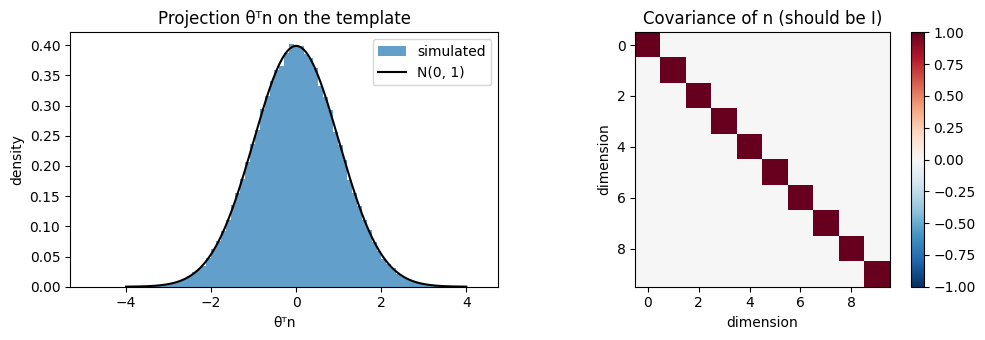

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

x = np.linspace(-4, 4, 200)
axes[0].hist(proj, bins=80, density=True, color="tab:blue", alpha=0.7, label="simulated")
axes[0].plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k", lw=1.5, label="N(0, 1)")
axes[0].set(title="Projection θᵀn on the template", xlabel="θᵀn", ylabel="density")
axes[0].legend()

im = axes[1].imshow(cov, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set(title="Covariance of n (should be I)", xlabel="dimension", ylabel="dimension")
fig.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

## 4. `observer_choose(images, theta, sigma, k=1)` → which images were chosen

**General rule (k of n).** On each trial the simulated person sees n images x₁ … xₙ and gives each one an internal score

$$u_i = \theta^\top x_i + \eta_i, \qquad \eta_i \sim N(0,\ \sigma^2)\ \text{independent across images and trials},$$

then picks the **k images with the highest scores**. So **`sigma` is the SD of the noise on each image's score** (per-image σ).

**Link to the 2IFC rule in the model.** With n = 2, k = 1 and images b + n, b − n:

$$u_1 > u_2 \iff 2\theta^\top n + (\eta_1 - \eta_2) > 0 \iff \theta^\top n + \varepsilon > 0, \quad \varepsilon = \tfrac{\eta_1 - \eta_2}{2} \sim N\!\left(0, \tfrac{\sigma^2}{2}\right).$$

So the model's 2IFC noise is **σ_model = σ / √2**, and P(pick b + n) = Φ(√2 · θᵀn / σ). When comparing with the predictions in §6 of the [model](../model/01-simulated-person-on-paper.md), use σ_model = `sigma` / √2.

**Other properties**
- The base b is shared by all images, so it adds the same θᵀb to every score and **never changes the choice** (linear observer).
- σ = 0: the person always picks the true top k by θᵀx.
- σ → ∞: choices become random, each image chosen with probability k/n.

**Shapes.** `images` is `(n, d)` for one trial or `(..., n, d)` for many (e.g. `(n_trials, n, d)`). The result is a boolean array `(..., n)` with exactly k `True` per trial.

**2IFC convention.** Images are always stacked as **`[base + n, base − n]`**, so column 0 is +n and column 1 is −n. `choices_to_sign` turns the boolean result into s_t = ±1 for `classification_image`.

In [9]:
def observer_choose(images, theta, sigma, k=1, rng=None):
    """Simulated linear observer: pick the k of n images with the highest noisy score.

    Score of image i on a trial: u_i = theta^T x_i + eta_i, eta_i ~ N(0, sigma^2), independent.

    Parameters
    ----------
    images : array, shape (n, d) or (..., n, d)
        The n images shown on each trial (leading axes = trials).
    theta : array, shape (d,)
        Hidden template.
    sigma : float >= 0
        SD of the internal noise on EACH image's score (per-image sigma), for any n and k.
        For a 2IFC pair (b + n, b - n) this equals the model's rule theta^T n + eps > 0
        with eps ~ N(0, sigma^2 / 2), i.e. sigma_model = sigma / sqrt(2).
    k : int, 1 <= k < n
        Number of images chosen per trial.
    rng : None, int or np.random.Generator, optional
        Seed or generator, for reproducible runs (passed to np.random.default_rng).

    Returns
    -------
    chosen : bool array, shape images.shape[:-1]; exactly k True per trial.
    """
    images = np.asarray(images, dtype=float)
    theta = np.asarray(theta, dtype=float)
    if images.ndim < 2:
        raise ValueError(f"images must have shape (..., n, d), got {images.shape}")
    n, d = images.shape[-2:]
    if theta.shape != (d,):
        raise ValueError(f"theta must have shape ({d},), got {theta.shape}")
    if isinstance(sigma, bool) or not sigma >= 0:
        raise ValueError(f"sigma must be >= 0, got {sigma!r}")
    _check_positive_int("k", k)
    if k >= n:
        raise ValueError(f"k must be < n = {n}, got {k!r}")
    rng = np.random.default_rng(rng)

    # einsum instead of `@`: avoids the false floating-point warnings that matmul gives with
    # Apple's Accelerate BLAS in some NumPy versions (section 3). After upgrading NumPy,
    # check whether `@` still warns.
    scores = np.einsum("...nd,d->...n", images, theta)
    scores = scores + sigma * rng.standard_normal(scores.shape)

    # argsort sorts all n scores; fine for n = 2 or ~10 images (argpartition would be faster for big n).
    top_k = np.argsort(-scores, axis=-1)[..., :k]
    chosen = np.zeros(scores.shape, dtype=bool)
    np.put_along_axis(chosen, top_k, True, axis=-1)
    return chosen


def choices_to_sign(chosen):
    """2IFC responses as s_t = +1 / -1.

    chosen : bool array, shape (N, 2), from observer_choose on images stacked as
             [base + n, base - n]  (column 0 = +n, column 1 = -n).
    """
    chosen = np.asarray(chosen, dtype=bool)
    if chosen.ndim != 2 or chosen.shape[1] != 2 or not (chosen.sum(axis=1) == 1).all():
        raise ValueError("chosen must have shape (N, 2) with exactly one True per row")
    return np.where(chosen[:, 0], 1, -1)

### Checks

In [10]:
from math import erf, sqrt
Phi = lambda z: 0.5 * (1 + erf(z / sqrt(2)))      # standard normal CDF

base = np.zeros(d)                                  # any base works for a linear observer
noise = make_noise(n_trials, d, rng)
images_2ifc = np.stack([base + noise, base - noise], axis=1)   # (n_trials, 2, d): column 0 = +n

# Shape, exactly one chosen per trial, and the +/-1 conversion
chosen = observer_choose(images_2ifc, theta, sigma=1.0, rng=rng)
assert chosen.shape == (n_trials, 2) and (chosen.sum(axis=1) == 1).all()
s = choices_to_sign(chosen)
assert set(np.unique(s)) <= {-1, 1} and np.array_equal(s == 1, chosen[:, 0])
print("first 10 responses s_t:", s[:10])

# sigma = 0: always the image with the larger theta^T x
proj_t = np.einsum("td,d->t", noise, theta)
assert np.array_equal(choices_to_sign(observer_choose(images_2ifc, theta, 0.0)), np.sign(proj_t))

# Per-image sigma: P(pick base + n) = Phi(sqrt(2) * theta^T n / sigma)
n_fixed = 0.5 * theta                               # a noise pattern with theta^T n = 0.5
reps, sigma = 100_000, 1.0
pair = np.broadcast_to(np.stack([n_fixed, -n_fixed]), (reps, 2, d))
p_hat = observer_choose(pair, theta, sigma, rng=rng)[:, 0].mean()
p_model = Phi(sqrt(2) * 0.5 / sigma)
print(f"P(pick base + n) with theta^T n = 0.5, sigma = 1: simulated {p_hat:.3f}, "
      f"Phi(sqrt(2) * 0.5) = {p_model:.3f}")
assert abs(p_hat - p_model) < 0.01

# Seeds: an int seed is reproducible
assert np.array_equal(observer_choose(images_2ifc, theta, 1.0, rng=42),
                      observer_choose(images_2ifc, theta, 1.0, rng=42))

# The base never changes the choice (same random numbers, shifted base)
shifted = images_2ifc + 5 * make_template(d, rng)
assert np.array_equal(observer_choose(images_2ifc, theta, 1.0, rng=7),
                      observer_choose(shifted,     theta, 1.0, rng=7))

# k of n, sigma = 0: picks exactly the true top k
n_img, k = 6, 2
imgs = make_noise(n_trials * n_img, d, rng).reshape(n_trials, n_img, d)
true_top = np.argsort(-np.einsum("tnd,d->tn", imgs, theta), axis=1)[:, :k]
picked = observer_choose(imgs, theta, 0.0, k=k)
assert (picked.sum(axis=1) == k).all()
assert all(set(np.flatnonzero(picked[t])) == set(true_top[t]) for t in range(n_trials))

# k of n, huge sigma: random, each image chosen with probability k/n
freq = observer_choose(np.broadcast_to(imgs[0], (reps, n_img, d)), theta, 1e6, k=k, rng=rng).mean(axis=0)
print(f"choice rates with sigma = 1e6 (expected k/n = {k/n_img:.3f}):", freq.round(3))
assert np.allclose(freq, k / n_img, atol=0.01)

# Bad input is rejected
for kwargs in ({"k": 0}, {"k": 2}, {"k": 1.5}, {"k": True}, {"sigma": -1}):
    args = dict(images=images_2ifc, theta=theta, sigma=1.0) | kwargs
    try:
        observer_choose(**args)
    except ValueError:
        pass
    else:
        raise AssertionError(f"observer_choose with {kwargs} should fail")
try:
    choices_to_sign(picked)                         # shape (N, 6) is not 2IFC
except ValueError:
    pass
else:
    raise AssertionError("choices_to_sign should reject non-2IFC input")
print("All checks passed.")

first 10 responses s_t: [-1 -1  1 -1 -1  1  1 -1  1 -1]
P(pick base + n) with theta^T n = 0.5, sigma = 1: simulated 0.761, Phi(sqrt(2) * 0.5) = 0.760
choice rates with sigma = 1e6 (expected k/n = 0.333): [0.333 0.335 0.334 0.331 0.334 0.332]
All checks passed.


### How choice depends on θᵀn and σ (2IFC)

Each curve is the simulated probability of picking *base + n* against θᵀn, compared with Φ(√2 · θᵀn / σ) for per-image σ. Larger σ flattens the curve: the same noise pattern gives a less reliable response.

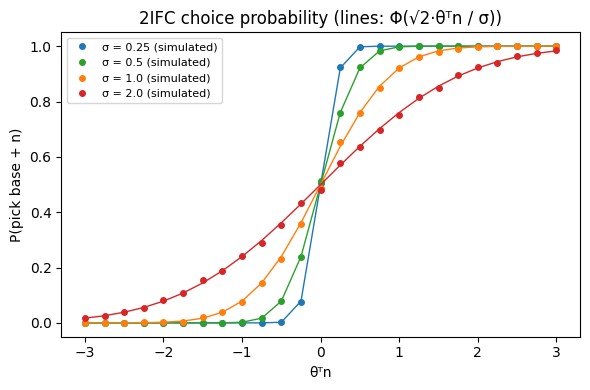

In [11]:
xs = np.linspace(-3, 3, 25)
reps = 4_000
fig, ax = plt.subplots(figsize=(6, 4))
for sig, color in zip((0.25, 0.5, 1.0, 2.0), ("tab:blue", "tab:green", "tab:orange", "tab:red")):
    p_sim = []
    for x in xs:
        pair = np.broadcast_to(np.stack([x * theta, -x * theta]), (reps, 2, d))
        p_sim.append(observer_choose(pair, theta, sig, rng=rng)[:, 0].mean())
    ax.plot(xs, p_sim, "o", ms=4, color=color, label=f"σ = {sig} (simulated)")
    ax.plot(xs, [Phi(sqrt(2) * x / sig) for x in xs], "-", color=color, lw=1)
ax.set(xlabel="θᵀn", ylabel="P(pick base + n)", title="2IFC choice probability (lines: Φ(√2·θᵀn / σ))")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. `classification_image(noise, choices)` → CI

$$\mathrm{CI} = \sum_{t=1}^{N} s_t\, n_t$$

- `noise` has shape `(N, d)`: row t is n_t, from `make_noise`.
- `choices` has shape `(N,)`: s_t = +1 if *base + n_t* was picked and −1 if *base − n_t* was picked, from `choices_to_sign`.
- The result has shape `(d,)`. It is a **sum**, not a mean; dividing by N changes the length only, so the cosine is the same.

## 6. `cosine(a, b)` → accuracy

$$\cos(a, b) = \frac{a^\top b}{\lVert a \rVert\, \lVert b \rVert}$$

Accuracy of the estimate is `cosine(CI, theta)`: 1 means the CI points exactly at the template, and 0 means it is unrelated.

In [12]:
def classification_image(noise, choices):
    """Return CI = sum_t s_t * n_t, shape (d,).

    Parameters
    ----------
    noise : array, shape (N, d)
        Noise pattern of each trial.
    choices : array, shape (N,)
        s_t = +1 if base + n_t was picked, -1 if base - n_t was picked (see choices_to_sign).
    """
    noise = np.asarray(noise, dtype=float)
    choices = np.asarray(choices)
    if noise.ndim != 2:
        raise ValueError(f"noise must have shape (N, d), got {noise.shape}")
    if choices.shape != (noise.shape[0],):
        raise ValueError(f"choices must have shape ({noise.shape[0]},), got {choices.shape}")
    # Rejects a boolean mask too: False would otherwise count as 0 and drop the trial.
    if choices.dtype == bool or not np.isin(choices, (-1, 1)).all():
        raise ValueError("choices must contain only +1 and -1; use choices_to_sign(chosen)")
    return np.sum(choices[:, np.newaxis] * noise, axis=0)


def cosine(a, b):
    """Return the cosine of the angle between two 1-D vectors of the same length."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if a.ndim != 1 or a.shape != b.shape:
        raise ValueError(f"a and b must be 1-D with the same shape, got {a.shape} and {b.shape}")
    norm_product = np.linalg.norm(a) * np.linalg.norm(b)
    if norm_product == 0:
        raise ValueError("cosine is undefined for a zero vector")
    # clip: rounding can push the ratio just outside [-1, 1]
    return float(np.clip(np.sum(a * b) / norm_product, -1.0, 1.0))

### Checks

In [13]:
# classification_image: small example worked by hand
hand_noise = np.array([[1.0, 2.0], [3.0, 4.0], [5.0, 7.0]])
assert np.array_equal(classification_image(hand_noise, np.array([1, -1, 1])), [3.0, 5.0])

# CI is the sum of the noise actually shown in each chosen image
chosen = observer_choose(images_2ifc, theta, sigma=1.0, rng=rng)
s = choices_to_sign(chosen)
ci = classification_image(noise, s)
assert ci.shape == (d,)
assert np.allclose(ci, images_2ifc[chosen].sum(axis=0))

# Flipping every response flips the CI
assert np.allclose(classification_image(noise, -s), -ci)

# cosine: known values
u, v = np.array([1.0, 0.0]), np.array([0.0, 2.0])
assert cosine(u, u) == 1.0 and cosine(u, -u) == -1.0 and cosine(u, v) == 0.0
assert np.isclose(cosine(u, np.array([1.0, 1.0])), 1 / np.sqrt(2))

# cosine ignores length, so sum vs. mean of the noise gives the same accuracy
assert np.isclose(cosine(ci, theta), cosine(ci / n_trials, theta))
assert np.isclose(cosine(ci, theta), cosine(theta, ci))

# Bad input is rejected
bad_calls = [
    lambda: classification_image(noise, s[:-1]),                # wrong length
    lambda: classification_image(noise, chosen[:, 0]),          # boolean mask, not +/-1
    lambda: classification_image(noise, np.zeros(n_trials)),    # values other than +/-1
    lambda: classification_image(noise[0], s),                  # noise is not (N, d)
    lambda: cosine(u, np.zeros(2)),                             # zero vector
    lambda: cosine(u, np.ones(3)),                              # different lengths
]
for call in bad_calls:
    try:
        call()
    except ValueError:
        pass
    else:
        raise AssertionError("bad input should raise ValueError")

print(f"One simulated person (N = {n_trials}, d = {d}, sigma = 1): cos(CI, theta) = {cosine(ci, theta):.3f}")
print("All checks passed.")

One simulated person (N = 300, d = 10, sigma = 1): cos(CI, theta) = 0.974
All checks passed.


### End-to-end check: does the pipeline match the prediction?

The full pipeline for **200 simulated persons** at each N, each with their own θ, noise and internal noise, reported as **mean ± SD** (model §6).

The prediction uses the model's σ, so the code runs with `sigma = √2 · σ_model`. Here σ_model = 1 and d = 10:

$$\cos(\mathrm{CI}, \theta) \approx \frac{1}{\sqrt{1 + (d-1)/(N a^2)}}, \qquad a^2 = \frac{2/\pi}{1 + \sigma_\text{model}^2}$$

    N   mean cos     SD   predicted    gap
    1      0.179  0.271       0.185 -0.006
    3      0.278  0.252       0.310 -0.032
   10      0.523  0.197       0.511 +0.012
   30      0.700  0.125       0.718 -0.017
  100      0.880  0.060       0.883 -0.003
  300      0.958  0.019       0.956 +0.002
 1000      0.986  0.006       0.986 +0.000


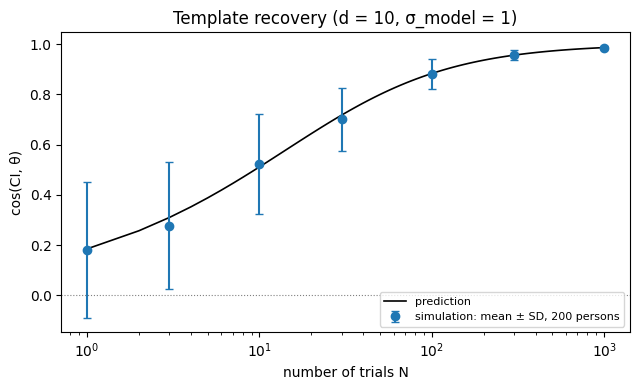

In [14]:
def run_person(n_trials, d, sigma, rng):
    """One simulated person through the whole 2IFC pipeline; returns cos(CI, theta)."""
    theta = make_template(d, rng)
    noise = make_noise(n_trials, d, rng)
    images = np.stack([noise, -noise], axis=1)      # base = 0: it cannot affect a linear observer
    s = choices_to_sign(observer_choose(images, theta, sigma, rng=rng))
    return cosine(classification_image(noise, s), theta)


def predicted_cosine(n_trials, d, sigma_model):
    a2 = (2 / np.pi) / (1 + sigma_model**2)
    return 1 / np.sqrt(1 + (d - 1) / (n_trials * a2))


n_persons, sigma_model = 200, 1.0
trial_counts = np.array([1, 3, 10, 30, 100, 300, 1000])
cosines = np.array([[run_person(N, d, np.sqrt(2) * sigma_model, rng) for _ in range(n_persons)]
                    for N in trial_counts])
means, sds = cosines.mean(axis=1), cosines.std(axis=1, ddof=1)
predicted = predicted_cosine(trial_counts, d, sigma_model)

print("    N   mean cos     SD   predicted    gap")
for N, m, sd, pred in zip(trial_counts, means, sds, predicted):
    print(f"{N:5d}     {m:6.3f} {sd:6.3f}      {pred:6.3f} {m - pred:+6.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
grid = np.unique(np.geomspace(1, 1000, 100).round().astype(int))
ax.plot(grid, predicted_cosine(grid, d, sigma_model), "k-", lw=1.2, label="prediction")
ax.errorbar(trial_counts, means, yerr=sds, fmt="o", color="tab:blue", capsize=3,
            label=f"simulation: mean ± SD, {n_persons} persons")
ax.axhline(0, color="gray", lw=0.8, ls=":")
ax.set(xscale="log", xlabel="number of trials N", ylabel="cos(CI, θ)",
       title=f"Template recovery (d = {d}, σ_model = {sigma_model:g})")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
d, n_persons = 10, 200
for N in [1, 3, 10, 30, 100, 300, 1000, 5000]:
    cos_values = [run_person(N, d, sigma=0.0, rng=rng) for _ in range(n_persons)]
    print(f"N = {N:4d}: mean cos = {np.mean(cos_values):.3f}, SD = {np.std(cos_values, ddof=1):.3f}, "
          f"predicted = {predicted_cosine(N, d, 0.0):.3f}")


N =    1: mean cos = 0.241, SD = 0.178, predicted = 0.257
N =    3: mean cos = 0.439, SD = 0.149, predicted = 0.418
N =   10: mean cos = 0.656, SD = 0.120, predicted = 0.644
N =   30: mean cos = 0.829, SD = 0.063, predicted = 0.824
N =  100: mean cos = 0.937, SD = 0.028, predicted = 0.936
N =  300: mean cos = 0.977, SD = 0.010, predicted = 0.977
N = 1000: mean cos = 0.993, SD = 0.003, predicted = 0.993


N = 5000: mean cos = 0.999, SD = 0.001, predicted = 0.999


## Experiments

| | Question | What varies | Held fixed |
|---|---|---|---|
| **E1** | How does accuracy grow with trials? | N: 10 → 2,000 | d = 10, σ = 1 |
| **E2** | How much does internal noise hurt? | σ: 0, 0.5, 1, 2 | d = 10 |
| **E3** | How does the number of dimensions matter? | d: 10, 50, 200 | σ = 1 |
| **E4** | Can you detect a real signal? | N and σ | d = 10 |

**Conventions**
- **σ in these experiments is the code's per-image `sigma`.** The prediction formula in the model doc uses σ_model = σ / √2, and `predicted_cosine_sigma` does that conversion.
- E1–E3 run **200 simulated persons** per setting and report **mean ± SD** across persons.
- Each experiment has its own seed, so it can be re-run on its own.

In [16]:
TRIAL_COUNTS = np.array([10, 20, 50, 100, 200, 500, 1000, 2000])
N_PERSONS = 200


def predicted_cosine_sigma(n_trials, d, sigma):
    """Predicted cos(CI, theta) for the code's per-image sigma."""
    return predicted_cosine(n_trials, d, sigma / np.sqrt(2))


def predicted_trials(target, d, sigma):
    """Predicted number of trials needed to reach cos(CI, theta) = target."""
    a2 = (2 / np.pi) / (1 + sigma**2 / 2)
    return (d - 1) / a2 * target**2 / (1 - target**2)


def sweep_trials(trial_counts, d, sigma, rng, n_persons=N_PERSONS):
    """Mean and SD of cos(CI, theta) across simulated persons, for each number of trials."""
    cosines = np.array([[run_person(int(N), d, sigma, rng) for _ in range(n_persons)]
                        for N in trial_counts])
    return cosines.mean(axis=1), cosines.std(axis=1, ddof=1)


def trials_to_reach(target, trial_counts, means):
    """Trials at which the measured mean cosine reaches target (interpolated on log N); nan if never."""
    rising = np.maximum.accumulate(means)
    if rising[-1] < target:
        return np.nan
    if rising[0] >= target:
        return float(trial_counts[0])
    return float(np.exp(np.interp(target, rising, np.log(trial_counts))))

### E1: How does accuracy grow with trials?

Prediction (P1): accuracy rises quickly at first and then slowly toward 1.

E1: d = 10, sigma = 1, 200 persons per N
    N   mean cos     SD   predicted     gap
   10      0.564  0.186       0.566  -0.002
   20      0.681  0.121       0.697  -0.016
   50      0.845  0.070       0.838  +0.007
  100      0.913  0.039       0.908  +0.005
  200      0.950  0.022       0.951  -0.001
  500      0.979  0.010       0.979  -0.000
 1000      0.990  0.004       0.990  +0.000
 2000      0.995  0.003       0.995  +0.000


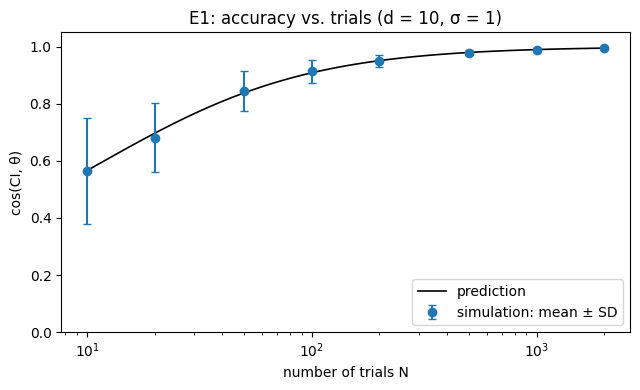

In [17]:
rng_e1 = np.random.default_rng(SEED + 1)
d_e1, sigma_e1 = 10, 1.0

means, sds = sweep_trials(TRIAL_COUNTS, d_e1, sigma_e1, rng_e1)
predicted = predicted_cosine_sigma(TRIAL_COUNTS, d_e1, sigma_e1)

print(f"E1: d = {d_e1}, sigma = {sigma_e1:g}, {N_PERSONS} persons per N")
print("    N   mean cos     SD   predicted     gap")
for N, m, sd, pred in zip(TRIAL_COUNTS, means, sds, predicted):
    print(f"{N:5d}     {m:6.3f} {sd:6.3f}      {pred:6.3f}  {m - pred:+6.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
grid = np.geomspace(TRIAL_COUNTS[0], TRIAL_COUNTS[-1], 100)
ax.plot(grid, predicted_cosine_sigma(grid, d_e1, sigma_e1), "k-", lw=1.2, label="prediction")
ax.errorbar(TRIAL_COUNTS, means, yerr=sds, fmt="o", color="tab:blue", capsize=3, label="simulation: mean ± SD")
ax.set(xscale="log", ylim=(0, 1.05), xlabel="number of trials N", ylabel="cos(CI, θ)",
       title=f"E1: accuracy vs. trials (d = {d_e1}, σ = {sigma_e1:g})")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### E2: How much does internal noise hurt?

Prediction (P2): the trials needed for a fixed accuracy scale with (1 + σ²/2) for per-image σ.

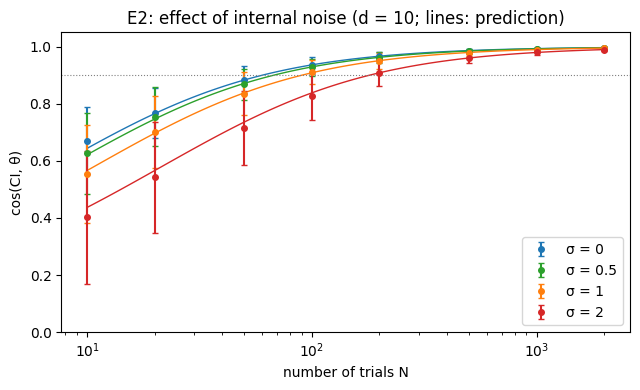

E2: d = 10, 200 persons per setting
sigma | cos at N=100 | cos at N=500 | trials to cos 0.9 (measured) | predicted | cost vs. sigma=0 (measured / predicted)
  0.0 |        0.935 |        0.986 |                           62 |        60 | 1.00 / 1.00
  0.5 |        0.927 |        0.984 |                           73 |        68 | 1.18 / 1.12
  1.0 |        0.910 |        0.979 |                           91 |        90 | 1.47 / 1.50
  2.0 |        0.828 |        0.961 |                          187 |       181 | 3.02 / 3.00


In [18]:
rng_e2 = np.random.default_rng(SEED + 2)
d_e2, sigmas_e2, target = 10, [0.0, 0.5, 1.0, 2.0], 0.9
colors_e2 = ["tab:blue", "tab:green", "tab:orange", "tab:red"]

fig, ax = plt.subplots(figsize=(6.5, 4))
grid = np.geomspace(TRIAL_COUNTS[0], TRIAL_COUNTS[-1], 100)
results_e2 = {}
for sig, color in zip(sigmas_e2, colors_e2):
    means, sds = sweep_trials(TRIAL_COUNTS, d_e2, sig, rng_e2)
    results_e2[sig] = means
    ax.plot(grid, predicted_cosine_sigma(grid, d_e2, sig), "-", color=color, lw=1)
    ax.errorbar(TRIAL_COUNTS, means, yerr=sds, fmt="o", ms=4, color=color, capsize=2, label=f"σ = {sig:g}")
ax.axhline(target, color="gray", lw=0.8, ls=":")
ax.set(xscale="log", ylim=(0, 1.05), xlabel="number of trials N", ylabel="cos(CI, θ)",
       title=f"E2: effect of internal noise (d = {d_e2}; lines: prediction)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

base_trials = trials_to_reach(target, TRIAL_COUNTS, results_e2[0.0])
print(f"E2: d = {d_e2}, {N_PERSONS} persons per setting")
print("sigma | cos at N=100 | cos at N=500 | trials to cos 0.9 (measured) | predicted | cost vs. sigma=0 (measured / predicted)")
for sig in sigmas_e2:
    measured = trials_to_reach(target, TRIAL_COUNTS, results_e2[sig])
    pred = predicted_trials(target, d_e2, sig)
    print(f"{sig:5.1f} | {results_e2[sig][3]:12.3f} | {results_e2[sig][5]:12.3f} | {measured:28.0f} | {pred:9.0f} | "
          f"{measured / base_trials:.2f} / {1 + sig**2 / 2:.2f}")

### E3: How does the number of dimensions matter?

Prediction (P3): the trials needed for a fixed accuracy scale with (d − 1). So the curves for different d should **collapse onto one curve** when plotted against N / (d − 1). The trial range extends to 5,000 here, because d = 200 needs about 2,000 trials to reach cos = 0.9.

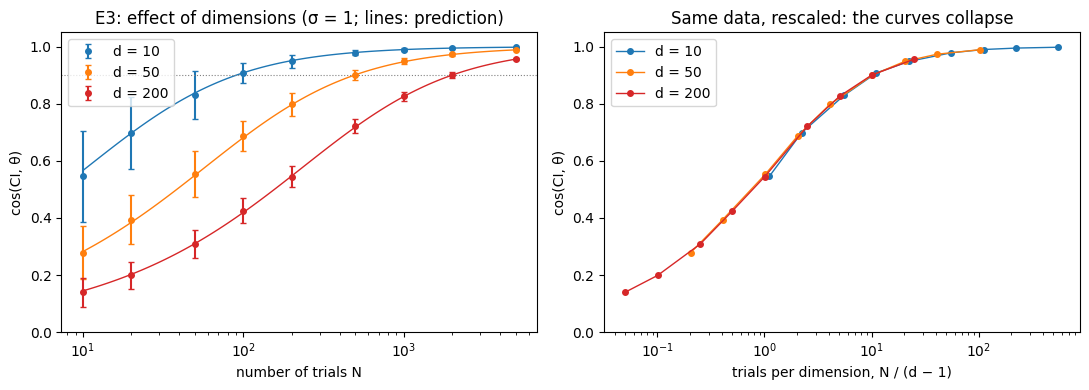

E3: sigma = 1, 200 persons per setting
    d | cos at N=100 | cos at N=1000 | trials to cos 0.9 (measured) | predicted | cost vs. d=10 (measured / predicted)
   10 |        0.908 |         0.990 |                           93 |        90 | 1.0 / 1.0
   50 |        0.687 |         0.948 |                          498 |       492 | 5.3 / 5.4
  200 |        0.425 |         0.826 |                         1992 |      1999 | 21.4 / 22.1


In [19]:
rng_e3 = np.random.default_rng(SEED + 3)
dims_e3, sigma_e3, target = [10, 50, 200], 1.0, 0.9
trials_e3 = np.append(TRIAL_COUNTS, 5000)
colors_e3 = ["tab:blue", "tab:orange", "tab:red"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
grid = np.geomspace(trials_e3[0], trials_e3[-1], 100)
results_e3 = {}
for dim, color in zip(dims_e3, colors_e3):
    means, sds = sweep_trials(trials_e3, dim, sigma_e3, rng_e3)
    results_e3[dim] = means
    axes[0].plot(grid, predicted_cosine_sigma(grid, dim, sigma_e3), "-", color=color, lw=1)
    axes[0].errorbar(trials_e3, means, yerr=sds, fmt="o", ms=4, color=color, capsize=2, label=f"d = {dim}")
    axes[1].plot(trials_e3 / (dim - 1), means, "o-", ms=4, lw=1, color=color, label=f"d = {dim}")
axes[0].axhline(target, color="gray", lw=0.8, ls=":")
axes[0].set(xscale="log", ylim=(0, 1.05), xlabel="number of trials N", ylabel="cos(CI, θ)",
            title=f"E3: effect of dimensions (σ = {sigma_e3:g}; lines: prediction)")
axes[1].set(xscale="log", ylim=(0, 1.05), xlabel="trials per dimension, N / (d − 1)", ylabel="cos(CI, θ)",
            title="Same data, rescaled: the curves collapse")
axes[0].legend(loc="upper left")
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

base_trials = trials_to_reach(target, trials_e3, results_e3[10])
print(f"E3: sigma = {sigma_e3:g}, {N_PERSONS} persons per setting")
print("    d | cos at N=100 | cos at N=1000 | trials to cos 0.9 (measured) | predicted | cost vs. d=10 (measured / predicted)")
for dim in dims_e3:
    measured = trials_to_reach(target, trials_e3, results_e3[dim])
    pred = predicted_trials(target, dim, sigma_e3)
    print(f"{dim:5d} | {results_e3[dim][3]:12.3f} | {results_e3[dim][6]:13.3f} | {measured:28.0f} | {pred:9.0f} | "
          f"{measured / base_trials:.1f} / {(dim - 1) / 9:.1f}")

### E4: Can you detect a real signal?

In a real experiment **θ is unknown**, so cos(CI, θ) cannot be computed. What we can ask is: *is this CI stronger than a person answering at random would produce?*

1. Keep the person's **exact noise patterns**.
2. Simulate **1,000 random responders** on those patterns and compute the length ‖CI‖ of each. This is the null distribution.
3. Express the person's ‖CI‖ as a robust z-score against the null, the idea behind **infoVal**:

$$z = \frac{\lVert \mathrm{CI} \rVert - \mathrm{median}(\text{null})}{1.4826 \cdot \mathrm{MAD}(\text{null})}$$

4. Call the signal **detected** if z > 1.96.

A good test should detect real observers often, and flag random responders only rarely. The exact infoVal formula should be checked against Brinkman et al. (2019).

E4, part 1: d = 10, N = 300, sigma = 1, 1000 random responders
null ||CI||: median = 54.8, 2.5-97.5% = 32.7 to 80.5
real observer:    ||CI|| =  178.6, z =    9.4
random responder: ||CI|| =   45.1, z =   -0.7


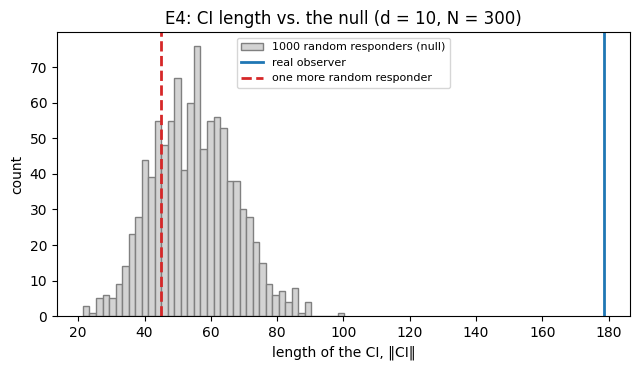

In [20]:
def null_ci_lengths(noise, n_null, rng):
    """Lengths of the CIs of n_null random responders who saw these noise patterns."""
    random_choices = 2.0 * rng.integers(0, 2, size=(n_null, noise.shape[0])) - 1.0
    return np.linalg.norm(np.einsum("rt,td->rd", random_choices, noise), axis=1)


def signal_z(ci_length, null_lengths):
    """Robust z-score of a CI's length against the null distribution (infoVal idea)."""
    median = np.median(null_lengths)
    mad = 1.4826 * np.median(np.abs(null_lengths - median))
    return (ci_length - median) / mad


def run_detection(n_trials, d, sigma, rng, n_null=1000):
    """z-score for one simulated person. sigma=None means a random responder."""
    noise = make_noise(n_trials, d, rng)
    if sigma is None:
        s = rng.choice([-1, 1], size=n_trials)
    else:
        theta = make_template(d, rng)
        s = choices_to_sign(observer_choose(np.stack([noise, -noise], axis=1), theta, sigma, rng=rng))
    ci_length = np.linalg.norm(classification_image(noise, s))
    return signal_z(ci_length, null_ci_lengths(noise, n_null, rng))


# Part 1: one real observer and one random responder, on the same noise patterns
rng_e4 = np.random.default_rng(SEED + 4)
d_e4, n_trials_e4, sigma_e4, n_null, threshold = 10, 300, 1.0, 1000, 1.96

theta_e4 = make_template(d_e4, rng_e4)
noise_e4 = make_noise(n_trials_e4, d_e4, rng_e4)
s_real = choices_to_sign(observer_choose(np.stack([noise_e4, -noise_e4], axis=1), theta_e4, sigma_e4, rng=rng_e4))
s_random = rng_e4.choice([-1, 1], size=n_trials_e4)
length_real = np.linalg.norm(classification_image(noise_e4, s_real))
length_random = np.linalg.norm(classification_image(noise_e4, s_random))
null_lengths = null_ci_lengths(noise_e4, n_null, rng_e4)

print(f"E4, part 1: d = {d_e4}, N = {n_trials_e4}, sigma = {sigma_e4:g}, {n_null} random responders")
print(f"null ||CI||: median = {np.median(null_lengths):.1f}, 2.5-97.5% = "
      f"{np.percentile(null_lengths, 2.5):.1f} to {np.percentile(null_lengths, 97.5):.1f}")
print(f"real observer:    ||CI|| = {length_real:6.1f}, z = {signal_z(length_real, null_lengths):6.1f}")
print(f"random responder: ||CI|| = {length_random:6.1f}, z = {signal_z(length_random, null_lengths):6.1f}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.hist(null_lengths, bins=40, color="lightgray", edgecolor="gray", label=f"{n_null} random responders (null)")
ax.axvline(length_real, color="tab:blue", lw=2, label="real observer")
ax.axvline(length_random, color="tab:red", lw=2, ls="--", label="one more random responder")
ax.set(xlabel="length of the CI, ‖CI‖", ylabel="count", title=f"E4: CI length vs. the null (d = {d_e4}, N = {n_trials_e4})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

E4, part 2: share of persons with z > 1.96 (d = 10, 200 persons, 1000 null runs each)
                    N=5      N=10     N=20     N=50     N=100    N=300  
             σ = 0  0.145    0.250    0.665    1.000    1.000    1.000  
             σ = 1  0.090    0.145    0.420    0.905    1.000    1.000  
             σ = 2  0.045    0.085    0.165    0.480    0.940    1.000  
  random responder  0.020    0.025    0.025    0.045    0.010    0.010  


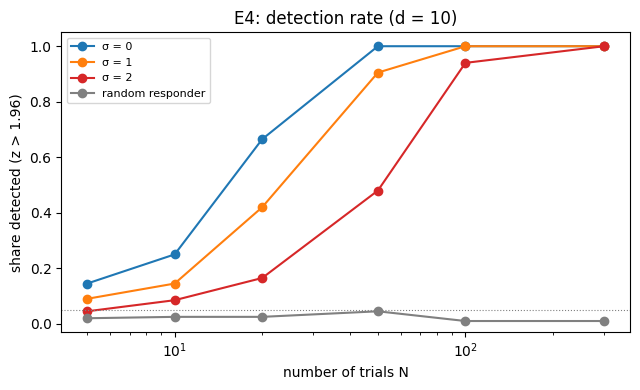

In [21]:
# Part 2: how often is the signal detected?
rng_e4b = np.random.default_rng(SEED + 5)
trials_e4 = np.array([5, 10, 20, 50, 100, 300])
groups_e4 = {"σ = 0": 0.0, "σ = 1": 1.0, "σ = 2": 2.0, "random responder": None}
colors_e4 = {"σ = 0": "tab:blue", "σ = 1": "tab:orange", "σ = 2": "tab:red", "random responder": "gray"}

rates_e4 = {}
for label, sig in groups_e4.items():
    z = np.array([[run_detection(int(N), d_e4, sig, rng_e4b, n_null) for _ in range(N_PERSONS)] for N in trials_e4])
    rates_e4[label] = (z > threshold).mean(axis=1)

print(f"E4, part 2: share of persons with z > {threshold} (d = {d_e4}, {N_PERSONS} persons, {n_null} null runs each)")
print(f"{'':>18}" + "".join(f"  N={N:<5d}" for N in trials_e4))
for label, rate in rates_e4.items():
    print(f"{label:>18}" + "".join(f"  {r:<7.3f}" for r in rate))

fig, ax = plt.subplots(figsize=(6.5, 4))
for label, rate in rates_e4.items():
    ax.plot(trials_e4, rate, "o-", color=colors_e4[label], label=label)
ax.axhline(0.05, color="gray", lw=0.8, ls=":")
ax.set(xscale="log", ylim=(-0.03, 1.05), xlabel="number of trials N", ylabel=f"share detected (z > {threshold})",
       title=f"E4: detection rate (d = {d_e4})")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()